# Лабораторная работа №2. Генерация карты из изображения со спутника

**Задача:** по спутниковому снимку получить схематическое изображение карты (дороги, водоёмы,
парки, застройка) — задача трансляции «изображение → изображение».

**Данные:** датасет `maps` из коллекции pix2pix (Berkeley): 1096 обучающих и 1098 валидационных пар
«снимок Google Maps — схема карты» по Нью-Йорку, каждая пара хранится как одно изображение 1200×600
(слева снимок, справа карта).

**Модель:** pix2pix (Isola et al., 2017) — условная GAN:
* генератор — U-Net со skip-соединениями между энкодером и декодером;
* дискриминатор — PatchGAN, оценивающий реалистичность отдельных фрагментов изображения
  при условии входного снимка;
* функция потерь генератора — $\mathcal{L}_{cGAN} + \lambda \cdot \mathcal{L}_{L1}$, $\lambda = 100$.

Обучение выполняется на CPU, поэтому изображения уменьшены до 128×128, число фильтров генератора
уменьшено вдвое (32…256 вместо 64…512), а число эпох ограничено. Структура сетей и функции потерь
при этом соответствуют статье.

In [1]:
import glob
import os
import time

# oneDNN-ядра TensorFlow падают на свёртках с пространственным размером 1×1 (дно U-Net) — отключаем их
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image

tf.random.set_seed(42)
np.random.seed(42)

DATA_DIR = os.path.join("..", "data", "maps")
CKPT_DIR = os.path.join("..", "data", "checkpoints", "lab2")
IMG_SIZE = 128
BATCH_SIZE = 4
EPOCHS = int(os.environ.get("LAB2_EPOCHS", 25))
N_VAL = 200

## 1. Загрузка данных

Каждое изображение делится пополам на вход (снимок) и цель (карту), обе половины уменьшаются до
128×128 и нормируются в диапазон $[-1, 1]$.

In [2]:
def load_pairs(folder, limit=None):
    files = sorted(glob.glob(os.path.join(folder, "*.jpg")), key=lambda p: int(os.path.basename(p)[:-4]))[:limit]
    sat, maps = [], []
    for p in files:
        img = Image.open(p).convert("RGB")
        w, h = img.size
        sat.append(np.asarray(img.crop((0, 0, w // 2, h)).resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)))
        maps.append(np.asarray(img.crop((w // 2, 0, w, h)).resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)))
    return np.stack(sat), np.stack(maps)


train_sat, train_map = load_pairs(os.path.join(DATA_DIR, "train"))
val_sat, val_map = load_pairs(os.path.join(DATA_DIR, "val"), N_VAL)
print("train:", train_sat.shape, " val:", val_sat.shape)


def to_tensor(x):
    return tf.cast(x, tf.float32) / 127.5 - 1.0


def to_image(x):
    return np.clip((np.asarray(x) + 1) / 2, 0, 1)

train: (1096, 128, 128, 3)  val: (200, 128, 128, 3)


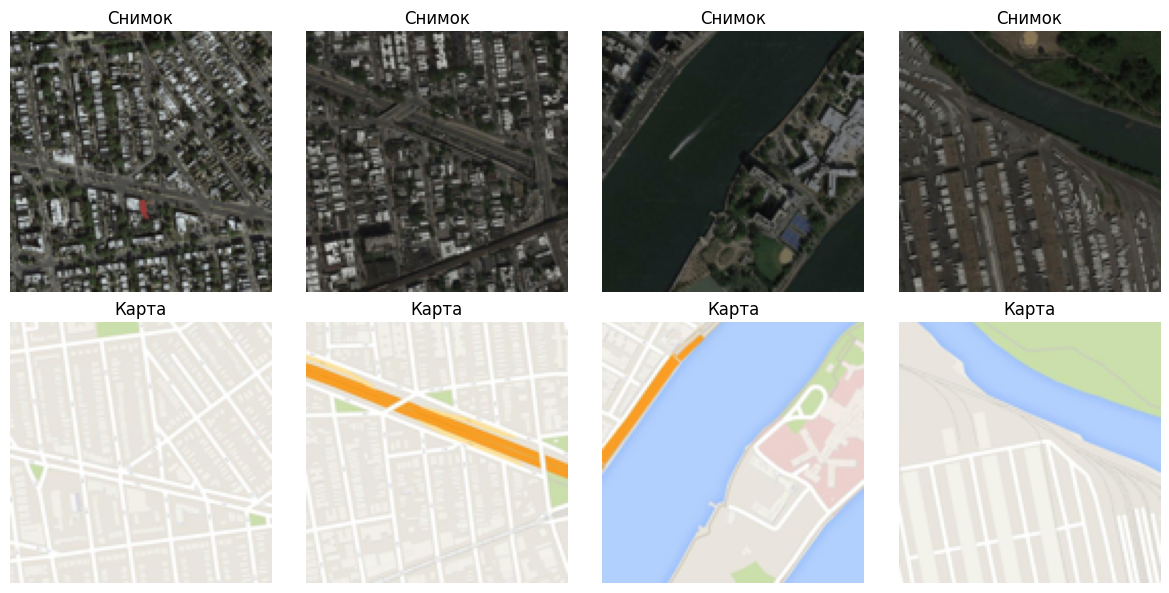

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axes[0, i].imshow(train_sat[i]); axes[0, i].set_title("Снимок")
    axes[1, i].imshow(train_map[i]); axes[1, i].set_title("Карта")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

Аугментация — случайное горизонтальное отражение пары (одинаковое для входа и цели).

In [4]:
def augment(sat, mp):
    if tf.random.uniform(()) > 0.5:
        sat, mp = tf.image.flip_left_right(sat), tf.image.flip_left_right(mp)
    return to_tensor(sat), to_tensor(mp)


train_ds = (tf.data.Dataset.from_tensor_slices((train_sat, train_map))
            .shuffle(len(train_sat)).map(augment).batch(BATCH_SIZE).prefetch(2))

## 2. Генератор U-Net

In [5]:
init = tf.random_normal_initializer(0.0, 0.02)


def down(filters, size=4, norm=True):
    block = tf.keras.Sequential()
    block.add(tf.keras.layers.Conv2D(filters, size, strides=2, padding="same", kernel_initializer=init, use_bias=False))
    if norm:
        block.add(tf.keras.layers.BatchNormalization())
    block.add(tf.keras.layers.LeakyReLU(0.2))
    return block


def up(filters, size=4, dropout=False):
    block = tf.keras.Sequential()
    block.add(tf.keras.layers.Conv2DTranspose(filters, size, strides=2, padding="same", kernel_initializer=init, use_bias=False))
    block.add(tf.keras.layers.BatchNormalization())
    if dropout:
        block.add(tf.keras.layers.Dropout(0.5))
    block.add(tf.keras.layers.ReLU())
    return block


def build_generator():
    inp = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    downs = [down(32, norm=False), down(64), down(128), down(256), down(256), down(256), down(256)]  # 128 -> 1
    ups = [up(256, dropout=True), up(256, dropout=True), up(256, dropout=True), up(128), up(64), up(32)]  # 1 -> 64
    x, skips = inp, []
    for d in downs:
        x = d(x)
        skips.append(x)
    for u, skip in zip(ups, reversed(skips[:-1])):
        x = tf.keras.layers.Concatenate()([u(x), skip])
    out = tf.keras.layers.Conv2DTranspose(3, 4, strides=2, padding="same", kernel_initializer=init, activation="tanh")(x)
    return tf.keras.Model(inp, out, name="unet_generator")


generator = build_generator()
print(f"Параметров генератора: {generator.count_params():,}")

Параметров генератора: 10,466,435


## 3. Дискриминатор PatchGAN

Дискриминатор получает пару (снимок, карта) и выдаёт карту 14×14 оценок «реальности» —
по одной на перекрывающийся фрагмент изображения.

In [6]:
def build_discriminator():
    sat = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="satellite")
    mp = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="map")
    x = tf.keras.layers.Concatenate()([sat, mp])
    x = down(64, norm=False)(x)    # 64
    x = down(128)(x)               # 32
    x = down(256)(x)               # 16
    x = tf.keras.layers.ZeroPadding2D()(x)
    x = tf.keras.layers.Conv2D(512, 4, kernel_initializer=init, use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.LeakyReLU(0.2)(x)
    x = tf.keras.layers.ZeroPadding2D()(x)
    out = tf.keras.layers.Conv2D(1, 4, kernel_initializer=init)(x)
    return tf.keras.Model([sat, mp], out, name="patchgan")


discriminator = build_discriminator()
print("Выход дискриминатора:", discriminator.output_shape)

Выход дискриминатора: (None, 14, 14, 1)


## 4. Функции потерь и шаг обучения

In [7]:
LAMBDA = 100
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
d_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)


@tf.function
def train_step(sat, target):
    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
        fake = generator(sat, training=True)
        d_real = discriminator([sat, target], training=True)
        d_fake = discriminator([sat, fake], training=True)

        gan_loss = bce(tf.ones_like(d_fake), d_fake)
        l1_loss = tf.reduce_mean(tf.abs(target - fake))
        g_loss = gan_loss + LAMBDA * l1_loss
        d_loss = bce(tf.ones_like(d_real), d_real) + bce(tf.zeros_like(d_fake), d_fake)

    g_opt.apply_gradients(zip(g_tape.gradient(g_loss, generator.trainable_variables), generator.trainable_variables))
    d_opt.apply_gradients(zip(d_tape.gradient(d_loss, discriminator.trainable_variables), discriminator.trainable_variables))
    return gan_loss, l1_loss, d_loss

## 5. Обучение

Эпоха 1/20: G_gan=2.384  L1=0.1813  D=0.692  (179 с)


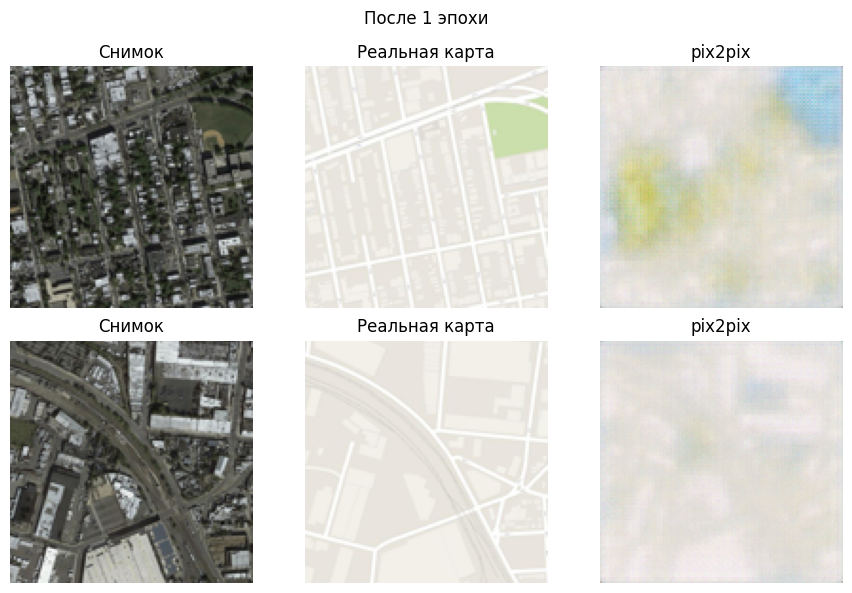

Эпоха 2/20: G_gan=1.785  L1=0.1101  D=0.793  (174 с)


Эпоха 3/20: G_gan=1.478  L1=0.1044  D=0.869  (180 с)


Эпоха 4/20: G_gan=1.908  L1=0.1039  D=0.729  (177 с)


Эпоха 5/20: G_gan=1.855  L1=0.1054  D=0.691  (174 с)


Эпоха 6/20: G_gan=2.004  L1=0.1056  D=0.664  (172 с)


...

Эпоха 16/20: G_gan=2.953  L1=0.0933  D=0.396  (173 с)


Эпоха 17/20: G_gan=2.956  L1=0.0934  D=0.482  (173 с)


Эпоха 18/20: G_gan=2.956  L1=0.0930  D=0.441  (163 с)


Эпоха 19/20: G_gan=2.826  L1=0.0932  D=0.471  (162 с)


Эпоха 20/20: G_gan=3.000  L1=0.0921  D=0.423  (173 с)


In [8]:
val_x, val_y = to_tensor(val_sat), to_tensor(val_map)


def show_examples(idx, title):
    pred = generator(tf.gather(val_x, idx), training=True)
    fig, axes = plt.subplots(len(idx), 3, figsize=(9, 3 * len(idx)))
    for r, i in enumerate(idx):
        for c, (img, name) in enumerate([(val_x[i], "Снимок"), (val_y[i], "Реальная карта"), (pred[r], "pix2pix")]):
            axes[r, c].imshow(to_image(img)); axes[r, c].set_title(name); axes[r, c].axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()


history = {"gan": [], "l1": [], "d": []}
for epoch in range(EPOCHS):
    start = time.time()
    losses = np.array([[float(v) for v in train_step(x, y)] for x, y in train_ds]).mean(axis=0)
    for key, v in zip(history, losses):
        history[key].append(v)
    print(f"Эпоха {epoch + 1}/{EPOCHS}: G_gan={losses[0]:.3f}  L1={losses[1]:.4f}  D={losses[2]:.3f}  ({time.time() - start:.0f} с)")
    if epoch == 0:
        show_examples([0, 1], "После 1 эпохи")

os.makedirs(CKPT_DIR, exist_ok=True)
generator.save_weights(os.path.join(CKPT_DIR, "generator.weights.h5"))

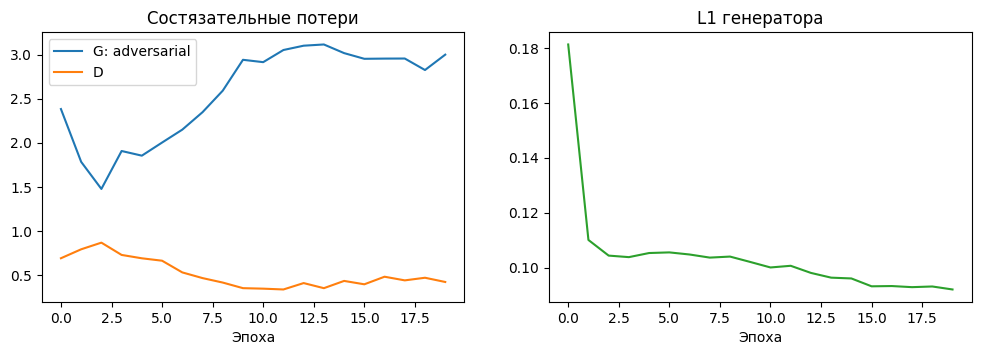

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(history["gan"], label="G: adversarial"); axes[0].plot(history["d"], label="D")
axes[0].set_title("Состязательные потери"); axes[0].legend(); axes[0].set_xlabel("Эпоха")
axes[1].plot(history["l1"], color="tab:green"); axes[1].set_title("L1 генератора"); axes[1].set_xlabel("Эпоха")
plt.show()

## 6. Результаты на валидационной выборке

Как и в статье, на этапе вывода dropout в генераторе остаётся включённым (`training=True`).

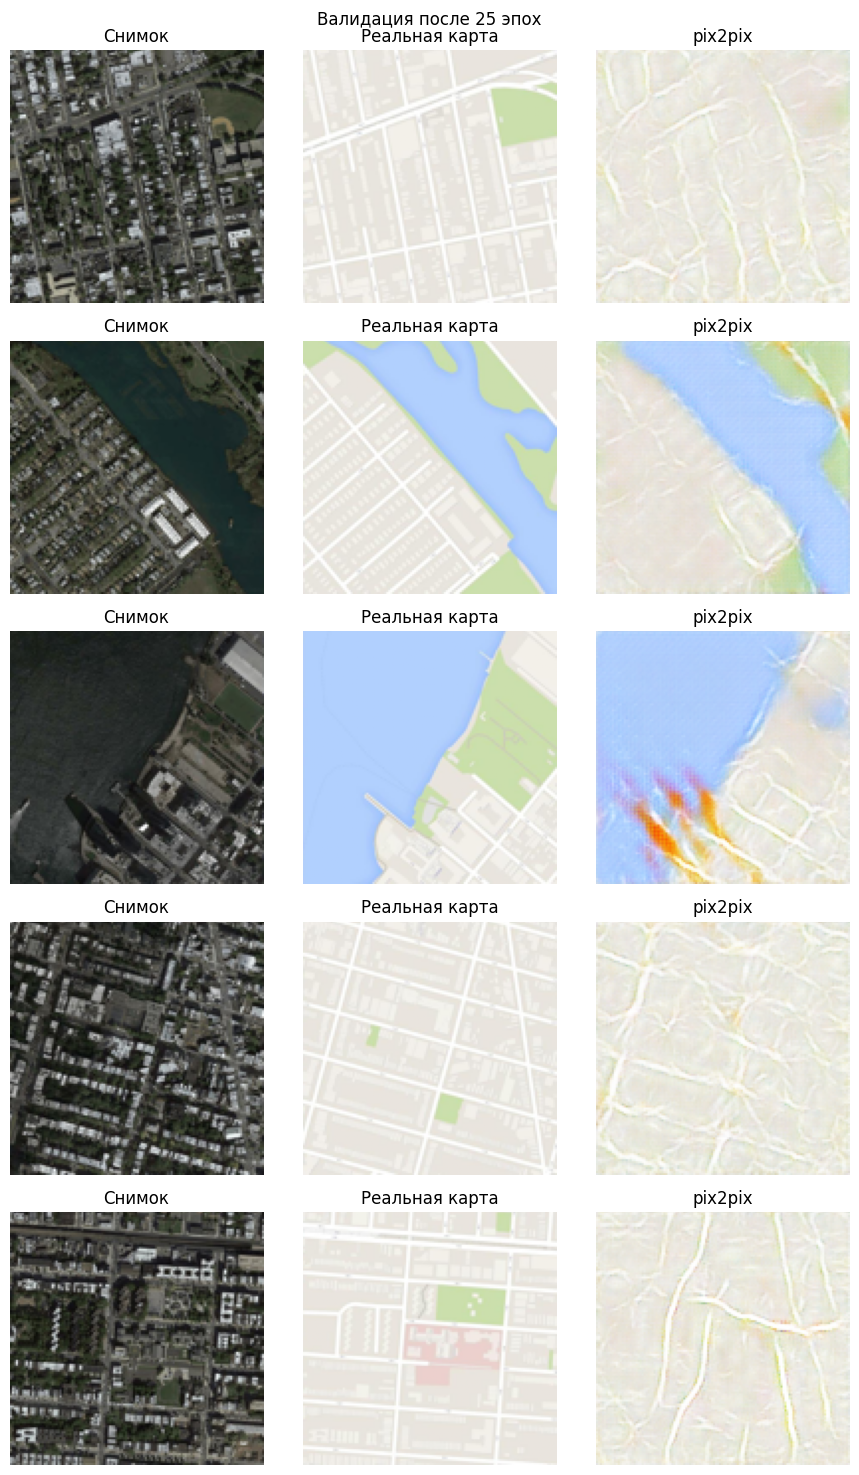

In [10]:
show_examples([0, 5, 17, 42, 101], f"Валидация после {EPOCHS} эпох")

### Количественная оценка

Сравниваются L1, PSNR и SSIM сгенерированной карты с реальной. Для ориентира приведено качество
тривиального решения — константной карты, равной среднему цвету обучающих карт.

In [11]:
def metrics(pred, target):
    p, t = (pred + 1) / 2, (target + 1) / 2
    return {
        "L1": float(tf.reduce_mean(tf.abs(p - t))),
        "PSNR, дБ": float(tf.reduce_mean(tf.image.psnr(p, t, 1.0))),
        "SSIM": float(tf.reduce_mean(tf.image.ssim(p, t, 1.0))),
    }


pred_val = tf.concat([generator(val_x[i:i + 20], training=True) for i in range(0, N_VAL, 20)], axis=0)
mean_map = tf.broadcast_to(tf.reduce_mean(to_tensor(train_map), axis=(0, 1, 2)), val_y.shape)


pd.DataFrame({"pix2pix": metrics(pred_val, val_y), "Средний цвет": metrics(mean_map, val_y)}).T.round(4)

,L1,"PSNR, дБ",SSIM
pix2pix,0.0402,24.4541,0.5483
Средний цвет,0.0437,25.1464,0.6388


По PSNR и SSIM константная карта оказывается даже лучше: ~80% площади карты — однотонный фон, и
«средний цвет» почти идеально совпадает с ним, тогда как любая ошибка в положении дороги штрафуется
дважды (дорога не там, где надо, и фон не там, где надо). Поэтому пиксельные метрики плохо отражают
смысл задачи — авторы pix2pix для карт оценивали результаты опросом людей.

Более содержательная оценка — **семантическая**: каждый пиксель реальной и сгенерированной карты
относится к классу по цвету (палитра карт фиксирована), после чего считается IoU по классам.

In [12]:
CLASSES = ["фон", "дорога", "магистраль", "вода", "парк"]


def map_classes(x):
    """Изображение карты в [-1, 1] -> номер класса каждого пикселя по цвету."""
    rgb = (np.asarray(x) + 1) * 127.5
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    cls = np.zeros(r.shape, np.int8)
    cls[np.minimum(np.minimum(r, g), b) >= 244] = 1          # белые улицы
    cls[(r - b > 60) & (r > 200)] = 2                         # оранжево-жёлтые магистрали
    cls[b - r > 40] = 3                                       # голубая вода
    cls[(g - b > 25) & (g > r)] = 4                           # зелёные парки
    return cls


def class_iou(pred, target):
    p, t = map_classes(pred), map_classes(target)
    res = {"Pixel accuracy": (p == t).mean()}
    for k, name in enumerate(CLASSES):
        union = ((p == k) | (t == k)).sum()
        res[f"IoU {name}"] = ((p == k) & (t == k)).sum() / union if union else np.nan
    res["mIoU"] = np.nanmean([res[f"IoU {n}"] for n in CLASSES])
    return res


pd.DataFrame({"pix2pix": class_iou(pred_val, val_y), "Средний цвет": class_iou(mean_map, val_y)}).T.round(3)

,Pixel accuracy,IoU фон,IoU дорога,IoU магистраль,IoU вода,IoU парк,mIoU
pix2pix,0.812,0.802,0.095,0.097,0.816,0.317,0.426
Средний цвет,0.794,0.794,0.000,0.000,0.000,0.000,0.159


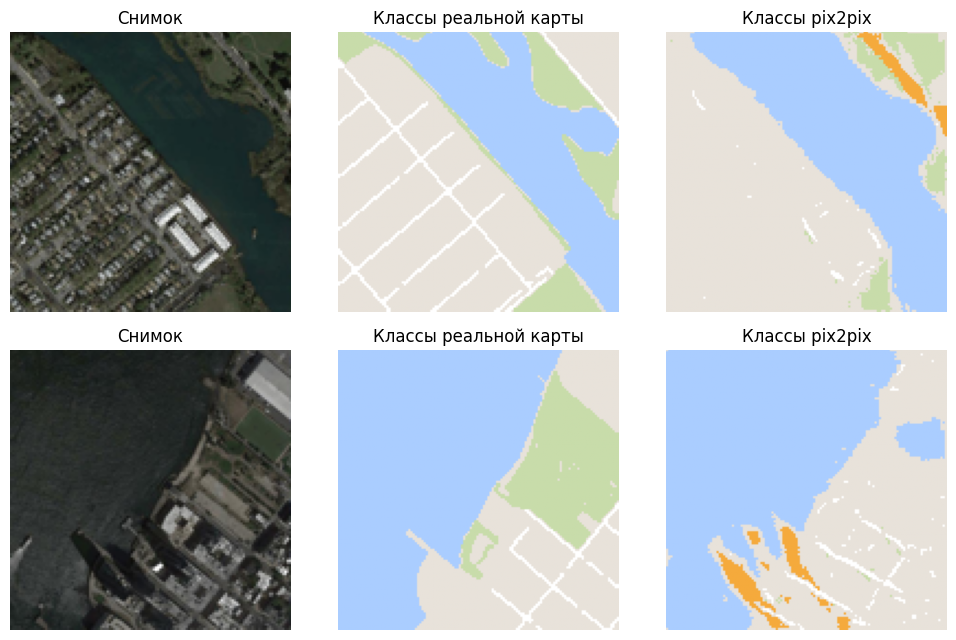

In [13]:
palette = np.array([[232, 226, 218], [255, 255, 255], [245, 170, 60], [170, 205, 255], [200, 220, 170]]) / 255
fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
for r, i in enumerate([5, 17]):
    for c, (img, name) in enumerate([(val_x[i], "Снимок"), (val_y[i], "Классы реальной карты"), (pred_val[i], "Классы pix2pix")]):
        axes[r, c].imshow(to_image(img) if c == 0 else palette[map_classes(img)])
        axes[r, c].set_title(name); axes[r, c].axis("off")
plt.tight_layout(); plt.show()

## 7. Применение к произвольному снимку

Функция `satellite_to_map` принимает путь к изображению (`.png`, `.bmp`, `.jpg`) и сохраняет
сгенерированную карту.

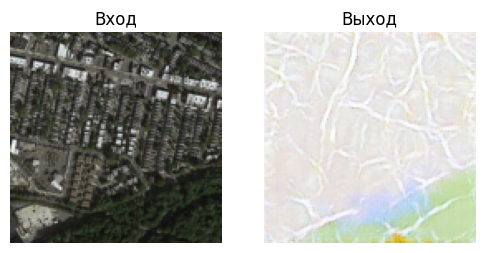

In [14]:
def satellite_to_map(path, out_path):
    img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)
    pred = generator(to_tensor(np.asarray(img))[None], training=True)[0]
    Image.fromarray((to_image(pred) * 255).astype(np.uint8)).save(out_path)
    return out_path


Image.fromarray(val_sat[3]).save("example_satellite.png")
satellite_to_map("example_satellite.png", "example_map.png")
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(Image.open("example_satellite.png")); axes[0].set_title("Вход")
axes[1].imshow(Image.open("example_map.png")); axes[1].set_title("Выход")
for ax in axes:
    ax.axis("off")
plt.show()

## Выводы

* Условная GAN pix2pix за 20 эпох обучения на CPU (1096 пар, 128×128) научилась переводить
  спутниковый снимок в схему карты в стиле Google Maps: модель выдаёт характерную палитру карты,
  уверенно выделяет водоёмы (IoU ≈ 0.82) и частично — парки (IoU ≈ 0.32).
* Слабое место — дороги: улицы на карте имеют ширину 2–3 пикселя при разрешении 128×128, и
  генератор рисует их размыто и не всегда там, где нужно (IoU ≈ 0.1). Кроме того, модель иногда
  «рисует» магистрали на тенях высотных зданий и у кромки воды.
* Пиксельные метрики (L1, PSNR, SSIM) для этой задачи малоинформативны: тривиальная однотонная карта
  выигрывает у модели по PSNR/SSIM, хотя не содержит ни одного объекта. Семантическая оценка по
  классам показывает реальный выигрыш: mIoU 0.43 против 0.16 у константы.
* В статье модель обучалась 200 эпох на изображениях 256×256 с полной шириной генератора; это
  основной резерв улучшения качества, особенно для тонких объектов вроде улиц.